# Telco Customer Churn:
**Talaba:** Jasurbek Makhammadjonov | **Dataset:** IBM Telco Customer Churn | **Split:** test 20%, random_state=42, stratify

## Day 0: Biznes muammosini tushunish
**Manbalar:** https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv

**Mijozlar kimlar?** Telecom kompaniyasi uy interneti (DSL/Fiber), telefon va qo'shimcha xizmatlar (xavfsizlik, zaxira, texnik yordam, TV, kino) sotadi. Mijozlar oylik yoki 1-2 yillik shartnoma bilan ishlaydi.

**Ketgan mijoz kompaniyaga nima yo'qotadi?** Har oylik daromad to'xtaydi; o'rniga yangi mijoz topish reklama, chegirma va sotuv xarajatini talab qiladi (odatda saqlab qolishdan qimmat); ketgan mijoz boshqalarga ta'sir qilishi mumkin.

**Ikki xato narxi.**
- **False negative (FN)**: model "qoladi" dedi, mijoz ketdi. Kompaniya hech narsa qilmadi, mijozning butun kelgusi daromadi yo'qoldi.
- **False positive (FP)**: model "ketadi" dedi, mijoz qoldi. Keraksiz chegirma yoki qo'ng'iroq xarajati, lekin mijoz saqlanadi.

**Qaysi xato yomonroq?** FN. FP narxi cheklangan va kichik (chegirma + operator vaqti), FN esa mijozning butun daromadi.

**Muammo turi:** binary classification. **Target:** `Churn` (Yes/No, keyin 1/0).
**Metrika:** asosiy **recall**, yordamchi **F1**. Accuracy yetarli emas: ma'lumotning 73.5% i "No", hammaga "qoladi" deydigan foydasiz model ham 73.5% accuracy oladi, recall esa 0 bo'ladi.

## Day 1: Yuklash va birinchi qarash

In [ ]:
import warnings
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
print(df.shape)
df.info()
df.head(3).T

(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

,0,1,2
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK
gender,Female,Male,Male
SeniorCitizen,0,0,0
Partner,Yes,No,No
Dependents,No,No,No
tenure,1,34,2
PhoneService,No,Yes,Yes
MultipleLines,No phone service,No,No
InternetService,DSL,DSL,DSL
OnlineSecurity,No,Yes,Yes


### Data dictionary (21 qator)
| № | Ustun | Real hayotdagi ma'nosi | Tip | Misol |
|---|---|---|---|---|
| 1 | customerID | Mijoz identifikatori | ID | 7590-VHVEG |
| 2 | gender | Jins | Kategorik | Female |
| 3 | SeniorCitizen | Keksa mijozmi (1/0) | Kategorik (0/1) | 0 |
| 4 | Partner | Sherigi bormi | Kategorik | Yes |
| 5 | Dependents | Qaramog'ida odam bormi | Kategorik | No |
| 6 | tenure | Necha oydan beri mijoz | Numerik | 34 |
| 7 | PhoneService | Telefon xizmati | Kategorik | No |
| 8 | MultipleLines | Bir nechta liniya | Kategorik (3 qiymat) | No phone service |
| 9 | InternetService | Internet turi | Kategorik | DSL |
| 10 | OnlineSecurity | Onlayn xavfsizlik | Kategorik | Yes |
| 11 | OnlineBackup | Onlayn zaxira | Kategorik | Yes |
| 12 | DeviceProtection | Qurilma himoyasi | Kategorik | No |
| 13 | TechSupport | Texnik yordam | Kategorik | No |
| 14 | StreamingTV | Oqimli TV | Kategorik | No |
| 15 | StreamingMovies | Oqimli kino | Kategorik | No |
| 16 | Contract | Shartnoma muddati | Kategorik (tartibli) | One year |
| 17 | PaperlessBilling | Elektron hisob-kitob | Kategorik | Yes |
| 18 | PaymentMethod | To'lov usuli | Kategorik (tartibsiz) | Electronic check |
| 19 | MonthlyCharges | Oylik to'lov | Numerik | 53.85 |
| 20 | TotalCharges | Jami to'lov | Numerik (hozir matn) | 1889.5 |
| 21 | Churn | Ketdimi (target) | Kategorik | Yes |

## Day 2: EDA (hech narsani o'zgartirmaymiz)

In [ ]:
# Bo'sh qiymatlar, bo'sh matn, TotalCharges, dublikatlar, target balansi
print("isna:", df.isna().sum().sum())
print("bo'sh matn:", (df.apply(lambda c: c.astype(str).str.strip() == "")).sum()[lambda s: s > 0].to_dict())
tc = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("TotalCharges NaN:", tc.isna().sum())
print(df.loc[tc.isna(), ["customerID","tenure","MonthlyCharges","TotalCharges","Churn"]])
print("dublikatlar (ID'siz):", df.drop(columns="customerID").duplicated().sum())
print(df["Churn"].value_counts()); print((df["Churn"].value_counts(normalize=True)*100).round(2))
# tenure=0 bo'lgan qatorlar soni (g'alati qiymat tekshiruvi)
print("tenure == 0:", (df["tenure"] == 0).sum())

isna: 0
bo'sh matn: {'TotalCharges': 11}
TotalCharges NaN: 11
      customerID  tenure  MonthlyCharges TotalCharges Churn
488   4472-LVYGI       0           52.55                 No
753   3115-CZMZD       0           20.25                 No
936   5709-LVOEQ       0           80.85                 No
1082  4367-NUYAO       0           25.75                 No
1340  1371-DWPAZ       0           56.05                 No
3331  7644-OMVMY       0           19.85                 No
3826  3213-VVOLG       0           25.35                 No
4380  2520-SGTTA       0           20.00                 No
5218  2923-ARZLG       0           19.70                 No
6670  4075-WKNIU       0           73.35                 No
6754  2775-SEFEE       0           61.90                 No
dublikatlar (ID'siz): 22
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64
tenure == 0: 11


In [ ]:
# Kategorik ustunlar: noyob qiymatlar soni
for c in df.select_dtypes(exclude="number").columns.drop(["customerID","TotalCharges"]):
    print(c, df[c].nunique(), df[c].unique().tolist())

gender 2 ['Female', 'Male']
Partner 2 ['Yes', 'No']
Dependents 2 ['No', 'Yes']
PhoneService 2 ['No', 'Yes']
MultipleLines 3 ['No phone service', 'No', 'Yes']
InternetService 3 ['DSL', 'Fiber optic', 'No']
OnlineSecurity 3 ['No', 'Yes', 'No internet service']
OnlineBackup 3 ['Yes', 'No', 'No internet service']
DeviceProtection 3 ['No', 'Yes', 'No internet service']
TechSupport 3 ['No', 'Yes', 'No internet service']
StreamingTV 3 ['No', 'Yes', 'No internet service']
StreamingMovies 3 ['No', 'Yes', 'No internet service']
Contract 3 ['Month-to-month', 'One year', 'Two year']
PaperlessBilling 2 ['Yes', 'No']
PaymentMethod 4 ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
Churn 2 ['No', 'Yes']


**Tartib bormi?** Faqat `Contract` tartibli (Month-to-month < One year < Two year). `PaymentMethod`, `InternetService`, `gender` tartibsiz. Qolganlari Yes/No yoki Yes/No/No service.

                  min      max     mean      50%
tenure           0.00    72.00    32.37    29.00
MonthlyCharges  18.25   118.75    64.76    70.35
TotalCharges    18.80  8684.80  2283.30  1397.48
skew:
 tenure            0.240
MonthlyCharges   -0.221
TotalCharges      0.962
dtype: float64


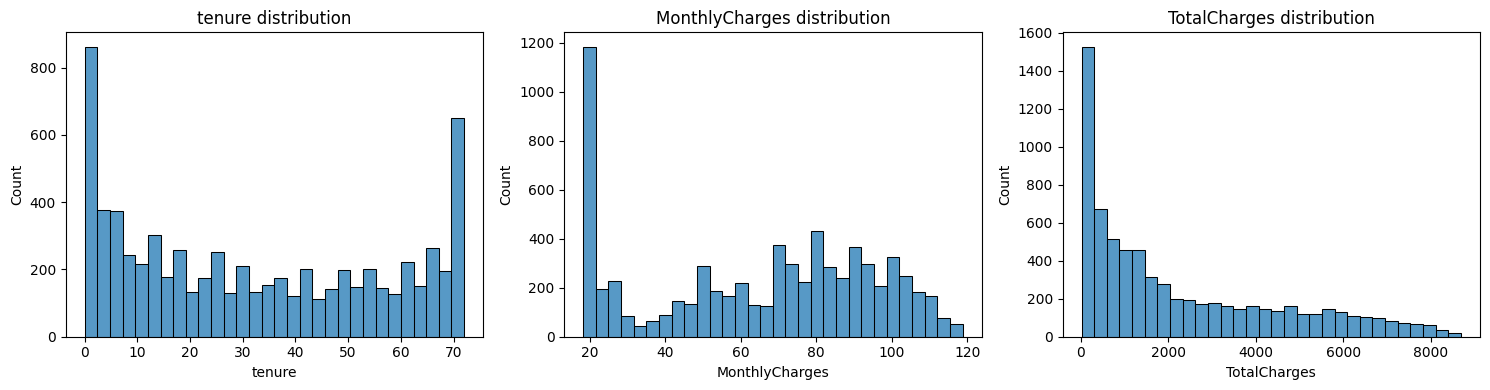

tenure outliers (IQR): 0
MonthlyCharges outliers (IQR): 0
TotalCharges outliers (IQR): 0


In [ ]:
eda = df.copy()
eda["TotalCharges"] = pd.to_numeric(eda["TotalCharges"], errors="coerce")
eda["Churn01"] = (eda["Churn"] == "Yes").astype(int)
num = ["tenure","MonthlyCharges","TotalCharges"]
print(eda[num].describe().T[["min","max","mean","50%"]].round(2))
print("skew:\n", eda[num].skew().round(3))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, num):
    sns.histplot(eda[c].dropna(), bins=30, ax=a); a.set_title(f"{c} distribution")
plt.tight_layout(); plt.show()
for c in num:
    s = eda[c].dropna(); q1, q3 = s.quantile([.25,.75]); i = q3-q1
    print(c, "outliers (IQR):", ((s < q1-1.5*i) | (s > q3+1.5*i)).sum())

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn01, dtype: float64


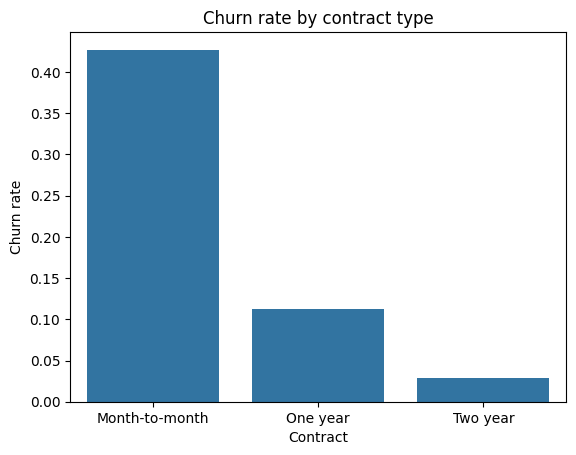

Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64


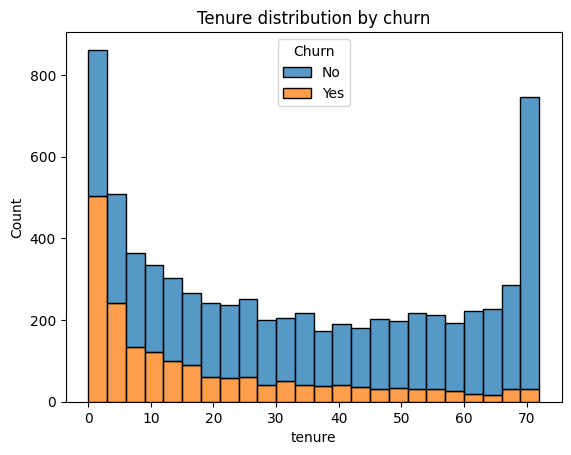

Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64


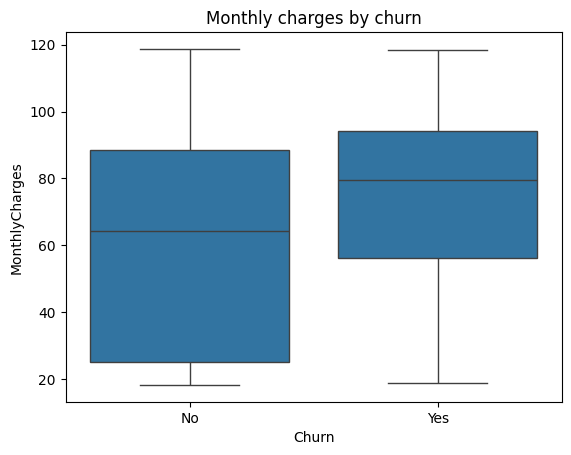

InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Churn01, dtype: float64


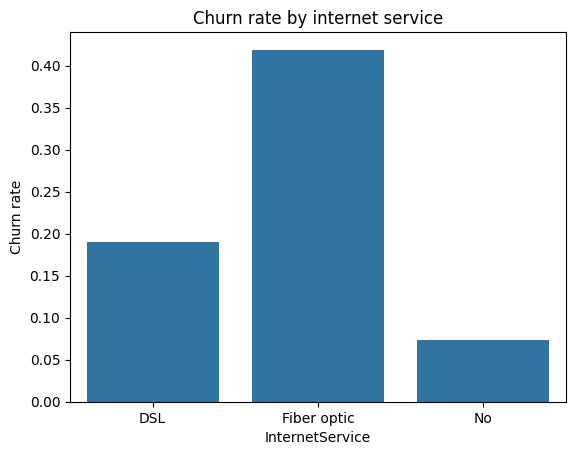

PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1
Name: Churn01, dtype: float64


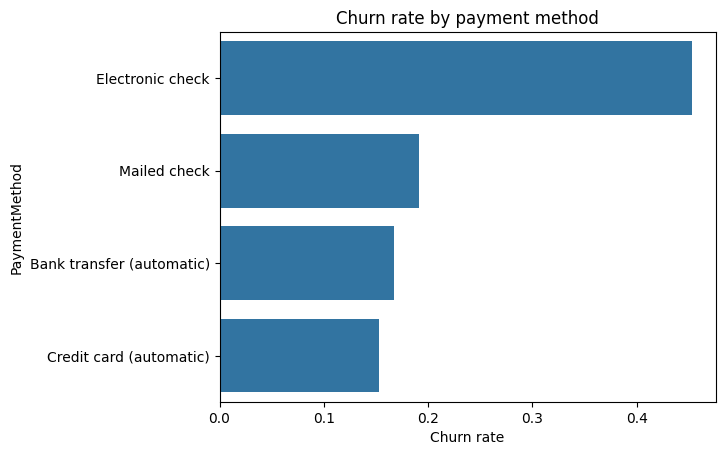

In [ ]:
order = ["Month-to-month","One year","Two year"]
print((eda.groupby("Contract")["Churn01"].mean()*100).round(1))
sns.barplot(data=eda, x="Contract", y="Churn01", order=order, errorbar=None)
plt.title("Churn rate by contract type"); plt.ylabel("Churn rate"); plt.show()

print(eda.groupby("Churn")["tenure"].median())
sns.histplot(data=eda, x="tenure", hue="Churn", bins=24, multiple="stack")
plt.title("Tenure distribution by churn"); plt.show()

print(eda.groupby("Churn")["MonthlyCharges"].median())
sns.boxplot(data=eda, x="Churn", y="MonthlyCharges")
plt.title("Monthly charges by churn"); plt.show()

print((eda.groupby("InternetService")["Churn01"].mean()*100).round(1))
sns.barplot(data=eda, x="InternetService", y="Churn01", errorbar=None)
plt.title("Churn rate by internet service"); plt.ylabel("Churn rate"); plt.show()

print((eda.groupby("PaymentMethod")["Churn01"].mean()*100).round(1))
sns.barplot(data=eda, y="PaymentMethod", x="Churn01", errorbar=None)
plt.title("Churn rate by payment method"); plt.xlabel("Churn rate"); plt.show()

### 5 ta biznes insight
1. **Shartnoma turi eng kuchli belgi:** Month-to-month mijozlarning 42.7% i ketgan, One year da 11.3%, Two year da 2.8%.
2. **Ketganlar yangi mijozlar:** ketganlarning tenure medianasi 10 oy, qolganlarniki 38 oy.
3. **Ketganlar ko'proq to'laydi:** oylik to'lov medianasi 79.65 va 64.43. Bu bog'liqlik, sabab emas (qimmat tarif Fiber optic bilan birga keladi).
4. **Fiber optic mijozlari eng ko'p ketadi:** 41.9%, DSL da 19.0%, internetsizlarda 7.4%.
5. **Electronic check bilan to'lovchilar ko'proq ketadi:** 45.3%, boshqa usullarda 15.2-19.1%.

**Numerik ustunlar:** IQR bo'yicha uchalasida ham outlier yo'q. `TotalCharges` o'ng tomonga cho'zilgan (skew 0.96): uzoq muddatli mijozlar ko'p to'lagan, bu tabiiy.

## Day 3: Tozalash

In [ ]:
# Dublikatlarni yaqindan ko'rish (customerID'siz)
cols = df.columns.drop("customerID")
dups = df[df.duplicated(subset=cols, keep=False)].sort_values(list(cols))
print("takror guruhlarga kirgan qatorlar:", len(dups), "| customerID noyobmi:", df["customerID"].is_unique)
print(dups["Churn"].value_counts())
print("Churn aralash guruhlar soni:", (dups.groupby(list(cols))["Churn"].nunique() > 1).sum())
print("tenure taqsimoti:\n", dups["tenure"].describe().round(1))
print(dups["Contract"].value_counts())
dups[["customerID","tenure","MonthlyCharges","TotalCharges","Contract","Churn"]]

takror guruhlarga kirgan qatorlar: 42 | customerID noyobmi: True
Churn
Yes    24
No     18
Name: count, dtype: int64
Churn aralash guruhlar soni: 0
tenure taqsimoti:
 count    42.0
mean      1.0
std       0.0
min       1.0
25%       1.0
50%       1.0
75%       1.0
max       1.0
Name: tenure, dtype: float64
Contract
Month-to-month    42
Name: count, dtype: int64


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
6491,9728-FTTVZ,1,69.20,69.2,Month-to-month,Yes
6764,7660-HDPJV,1,69.20,69.2,Month-to-month,Yes
4495,4702-IOQDC,1,70.10,70.1,Month-to-month,Yes
6267,0328-GRPMV,1,70.10,70.1,Month-to-month,Yes
5522,2619-WFQWU,1,70.15,70.15,Month-to-month,Yes
5759,9985-MWVIX,1,70.15,70.15,Month-to-month,Yes
542,2866-IKBTM,1,19.55,19.55,Month-to-month,No
1491,8605-ITULD,1,19.55,19.55,Month-to-month,No
5170,7721-DVEKZ,1,19.65,19.65,Month-to-month,No
6774,0970-QXPXW,1,19.65,19.65,Month-to-month,No


In [ ]:
df_clean = df.drop(columns="customerID").copy()
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce")
df_drop = df_clean.dropna(subset=["TotalCharges"]).copy()          # A: o'chirish
df_fill = df_clean.copy(); df_fill["TotalCharges"] = df_fill["TotalCharges"].fillna(0)   # B: 0 bilan
for name, d in [("drop", df_drop), ("fill0", df_fill)]:
    print(name, d.shape, round((d["Churn"]=="Yes").mean()*100, 2), round(d["TotalCharges"].mean(), 2))
print("Dublikatlar (ID olib tashlangandan keyin):", df_fill.duplicated().sum())
df_fill["Churn"] = df_fill["Churn"].map({"No":0, "Yes":1})
df_final = df_fill
print(df_final.shape, df_final.isna().sum().sum()); print(df_final.dtypes.value_counts())

drop (7032, 20) 26.58 2283.3
fill0 (7043, 20) 26.54 2279.73
Dublikatlar (ID olib tashlangandan keyin): 22
(7043, 20) 0
object     15
int64       3
float64     2
Name: count, dtype: int64


### Cleaning log
| Problem | Action | Reason |
|---|---|---|
| `customerID` ma'no bermaydi | Olib tashlandi | Noyob ID, mijoz xususiyati emas; model yodlab olishi mumkin |
| `TotalCharges` dtype object | `to_numeric(errors="coerce")` | Aslida son; 11 ta bo'sh matn tufayli matn bo'lgan |
| 11 ta bo'sh `TotalCharges` | 0 bilan to'ldirildi (o'chirish bilan taqqoslandi) | Hammasida tenure=0, hali hisob olmagan; o'chirish yangi mijozlarni yo'qotadi. Cheklov: ularning Churn=No belgisi to'liq ishonchli emas |
| 22 ta takror qator | Saqlandi | customerID lari har xil, hammasi tenure=1 va Month-to-month, 0 ta aralash-Churn guruh, tasodifiy mos kelish; o'chirish haqiqiy mijozlarni yo'qotadi |
| Outlier | Hech narsa qilinmadi | IQR bo'yicha 3 ustunda ham 0 ta |
| `Churn` matn | 1/0 ga o'zgartirildi | Modellar son talab qiladi |

## Day 4: Encoding
**Label/Ordinal:** har kategoriyaga bitta son. Tartibli ustunda (Contract: 0<1<2) to'g'ri, tartibsizda model sun'iy tartib "ko'radi".
**One-Hot:** har kategoriya uchun 0/1 ustun. Tartib yo'q, lekin ustun soni oshadi. `drop_first=True` dummy variable trap'dan saqlaydi.

| PaymentMethod | Electronic check | Mailed check | Bank transfer |
|---|---|---|---|
| Electronic check | 1 | 0 | 0 |
| Mailed check | 0 | 1 | 0 |
| Credit card (automatic) | 0 | 0 | 0 |

### Qarorlar jadvali
| Ustun | Tartib? | Version A | Version B |
|---|---|---|---|
| gender | Yo'q | One-Hot (1 ustun) | Female=0, Male=1 |
| Partner, Dependents, PhoneService, PaperlessBilling | Binary | 1 ustun | No=0, Yes=1 |
| Contract | **Ha** | One-Hot (2 ustun) | **Ordinal 0/1/2** |
| InternetService, PaymentMethod, MultipleLines, 6 ta xizmat ustuni | Yo'q | One-Hot | Label (alifbo bo'yicha) |

### Qaysi modellarga label encoding zarar qiladi?
- **LogReg, KNN:** kodlarni son sifatida ishlatadi (vazn va masofa), tartibsiz ustunda sun'iy tartib zarar beradi.
- **Random Forest:** "kod ≤ k" bo'linishlari bilan istalgan guruhni ajratadi, shuning uchun odatda zarar qilmaydi.

### Yana 2 encoding turi
- **Frequency encoding:** kategoriya o'rniga uchrash ulushi. Kategoriya juda ko'p bo'lganda foydali; ikki kategoriya bir xil chastotada bo'lsa farqlanmaydi.
- **Target encoding:** kategoriya o'rniga shu kategoriyadagi target o'rtachasi. Kuchli, lekin leakage xavfi yuqori: faqat train'dan, split'dan keyin (odatda CV ichida) hisoblanadi.

**Eslatma:** "No internet service"/"No phone service" qiymatlari `InternetService`/`PhoneService` ma'lumotini takrorlaydi. Lab uchta guruhni ko'rishni so'raydi, shuning uchun saqladik.

In [ ]:
from sklearn.preprocessing import OrdinalEncoder
cat_cols = df_final.select_dtypes(exclude="number").columns.tolist()
print(len(cat_cols), cat_cols)
A = pd.get_dummies(df_final, columns=cat_cols, drop_first=True, dtype=int)
B = df_final.copy()
B["Contract"] = B["Contract"].map({"Month-to-month":0, "One year":1, "Two year":2})
B["gender"] = B["gender"].map({"Female":0, "Male":1})
for c in ["Partner","Dependents","PhoneService","PaperlessBilling"]:
    B[c] = B[c].map({"No":0, "Yes":1})
rest = [c for c in cat_cols if c not in ["Contract","gender","Partner","Dependents","PhoneService","PaperlessBilling"]]
B[rest] = OrdinalEncoder().fit_transform(B[rest]).astype(int)
print("A:", A.shape, "B:", B.shape, "| NaN:", A.isna().sum().sum(), B.isna().sum().sum())
print(A.dtypes.value_counts()); print(B.dtypes.value_counts())

15 ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
A: (7043, 31) B: (7043, 20) | NaN: 0 0
int64      29
float64     2
Name: count, dtype: int64
int64      18
float64     2
Name: count, dtype: int64


**Shakl farqi:** A (7043, 31) da 30 feature, B (7043, 20) da 19 feature. One-Hot 11 ta qo'shimcha ustun qo'shdi; Ordinal ustun sonini o'zgartirmaydi.

## Day 5: Scaling
### Qo'lda hisoblash: [10, 20, 30, 40, 100]
- **Standard:** mean=40, std=√(5000/5)=31.62 → −0.95, −0.63, −0.32, 0, 1.90
- **MinMax:** min=10, max=100 → 0, 0.11, 0.22, 0.33, 1
- **Robust:** median=30, Q1=20, Q3=40, IQR=20 → −1, −0.5, 0, 0.5, 3.5

Katta qiymat (100) MinMax'da qolganlarni 0-0.33 ga siqdi; Robust'da qolganlar −1…0.5 oralig'ida qoldi.

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
t = np.array([[10],[20],[30],[40],[100]])
for S in (StandardScaler, MinMaxScaler, RobustScaler):
    print(S.__name__, S().fit_transform(t).ravel().round(2))   # qo'lda hisobni tekshirish

StandardScaler [-0.95 -0.63 -0.32  0.    1.9 ]
MinMaxScaler [0.   0.11 0.22 0.33 1.  ]
RobustScaler [-1.  -0.5  0.   0.5  3.5]


In [ ]:
from sklearn.model_selection import train_test_split
num_cols = ["tenure","MonthlyCharges","TotalCharges"]
scalers = {"standard": StandardScaler, "minmax": MinMaxScaler, "robust": RobustScaler}
def split(D):
    X, y = D.drop(columns="Churn"), D["Churn"]
    return train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
data = {}
for ver, D in [("A", A), ("B", B)]:
    Xtr, Xte, ytr, yte = split(D)
    data[(ver,"none")] = (Xtr.copy(), Xte.copy(), ytr, yte)
    for sname, S in scalers.items():
        sc = S(); Xtr_s, Xte_s = Xtr.copy(), Xte.copy()
        Xtr_s[num_cols] = sc.fit_transform(Xtr[num_cols])   # fit: faqat train
        Xte_s[num_cols] = sc.transform(Xte[num_cols])       # test: faqat transform
        data[(ver,sname)] = (Xtr_s, Xte_s, ytr, yte)
Xtr, Xte, ytr, yte = data[("A","none")]
print(Xtr.shape, Xte.shape, ytr.mean().round(4), yte.mean().round(4))
print("A va B bir xil split:", (data[("A","none")][3].index == data[("B","none")][3].index).all())
print("none\n", Xtr[num_cols].agg(["min","max","mean","std"]).T.round(3))
for s in scalers:
    print(s, "\n", data[("A", s)][0][num_cols].agg(["min","max","mean","std"]).T.round(3))

(5634, 30) (1409, 30) 0.2654 0.2654
A va B bir xil split: True
none
                  min      max      mean       std
tenure           0.0    72.00    32.485    24.569
MonthlyCharges  18.4   118.75    64.930    30.138
TotalCharges     0.0  8684.80  2299.335  2279.204
standard 
                   min    max  mean  std
tenure         -1.322  1.608  -0.0  1.0
MonthlyCharges -1.544  1.786  -0.0  1.0
TotalCharges   -1.009  2.802   0.0  1.0
minmax 
                 min  max   mean    std
tenure          0.0  1.0  0.451  0.341
MonthlyCharges  0.0  1.0  0.464  0.300
TotalCharges    0.0  1.0  0.265  0.262
robust 
                   min    max   mean    std
tenure         -0.630  0.935  0.076  0.534
MonthlyCharges -0.959  0.888 -0.103  0.555
TotalCharges   -0.406  2.124  0.263  0.664


### Data leakage
Leakage: model train paytida test ma'lumotidan yashirin ma'lumot olishi; natija yaxshi ko'rinadi, lekin real hayotda bunday bo'lmaydi. Agar scaler butun ma'lumotga `fit` qilinsa, mean/std/min/max ichiga test qatorlari kirib qoladi.
**To'g'ri tartib:** 1) `train_test_split`, 2) scaler faqat train'ga `fit`, 3) test'ga faqat `transform`. Kodimiz shunday. Faqat `tenure`, `MonthlyCharges`, `TotalCharges` scale qilindi; 0/1 ustunlar, kategorik kodlar va target scale qilinmadi.

## Day 6: Tajribalar (3 model × 2 encoding × 4 scaling = 24)
**Metrika:** asosiy recall, yordamchi F1. Accuracy yetarli emas: ma'lumotning 73.5% i "No", hammaga "No" deydigan model 73.5% accuracy oladi. Test'da ~374 ta ketuvchi mijoz bor, shuning uchun recall'dagi 0.0027 farq faqat 1 ta mijoz.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score
models = {"LogReg": lambda: LogisticRegression(max_iter=1000, random_state=42),
          "KNN": lambda: KNeighborsClassifier(),
          "RandomForest": lambda: RandomForestClassifier(random_state=42)}
rows = []
for (ver, sname), (Xtr, Xte, ytr, yte) in data.items():
    for mname, make in models.items():
        with warnings.catch_warnings(record=True) as w:
            warnings.simplefilter("always")
            p = make().fit(Xtr, ytr).predict(Xte)
        rows.append({"model": mname, "encoding": "OneHot" if ver=="A" else "Ordinal", "scaler": sname,
                     "accuracy": accuracy_score(yte,p), "F1": f1_score(yte,p), "recall": recall_score(yte,p),
                     "conv_warning": sum("onverge" in str(x.message) for x in w)})
results = pd.DataFrame(rows).sort_values("recall", ascending=False).reset_index(drop=True)
print(len(results)); print(results.round(4).to_string())

24
           model encoding    scaler  accuracy      F1  recall  conv_warning
0         LogReg   OneHot  standard    0.8062  0.6049  0.5588             0
1         LogReg   OneHot      none    0.8048  0.6020  0.5561             1
2         LogReg  Ordinal      none    0.7991  0.5940  0.5535             1
3         LogReg   OneHot    robust    0.8041  0.6000  0.5535             0
4            KNN   OneHot  standard    0.7630  0.5523  0.5508             0
5         LogReg  Ordinal  standard    0.7999  0.5925  0.5481             0
6         LogReg   OneHot    minmax    0.7991  0.5916  0.5481             0
7            KNN   OneHot    robust    0.7551  0.5418  0.5455             0
8         LogReg  Ordinal    robust    0.7984  0.5884  0.5428             0
9         LogReg  Ordinal    minmax    0.7991  0.5893  0.5428             0
10           KNN   OneHot    minmax    0.7480  0.5286  0.5321             0
11           KNN  Ordinal  standard    0.7594  0.5324  0.5160             0
12       

### Tahlil
**Scaling yordam berdimi?**
- **KNN:** ha, katta. OneHot recall 0.4305 (scalersiz) → 0.5508 (standard). KNN masofaga asoslangan; scalersiz `TotalCharges` (0-8684) masofani deyarli yolg'iz belgilaydi.
- **LogReg:** deyarli yo'q (0.5481-0.5588, ±1-2 mijoz). Scaling asosan optimizatsiyaga (konvergensiya) ta'sir qiladi; `conv_warning` ustuni shuni ko'rsatadi.
- **Random Forest:** o'zgarmadi (Ordinal 0.5107 hammasida). Daraxt "ustun ≤ chegara" deb bo'ladi, scaler tartibni o'zgartirmaydi.

**Encoding muhimmi?**
- **KNN:** ha. OneHot Ordinal'dan ~3.5-3.8 punkt yaxshi: Ordinal kodlar sun'iy masofa yaratadi.
- **LogReg:** OneHot biroz oldinda (~0.5-1 punkt), farq kichik.
- **Random Forest:** Ordinal ~1 punkt oldinda (4-5 mijoz farqi). Sababi ehtimol: OneHot ma'lumotni ko'p siyrak ustunga bo'ladi. Bu faraz.

**Cheklov:** hamma natijalar bitta split'ga asoslangan; kichik farqlar tasodif bo'lishi mumkin.

## Day 7: Yakuniy model, bonus va top omillar

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
Xtr, Xte, ytr, yte = data[("A","standard")]
cand = {"LogReg": LogisticRegression(max_iter=1000, random_state=42),
        "LogReg balanced": LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced"),
        "RF": RandomForestClassifier(random_state=42),
        "RF balanced": RandomForestClassifier(random_state=42, class_weight="balanced")}
for name, m in cand.items():
    p = m.fit(Xtr, ytr).predict(Xte)
    print(f"{name:16} acc={accuracy_score(yte,p):.4f} F1={f1_score(yte,p):.4f} recall={recall_score(yte,p):.4f}")
final = cand["LogReg balanced"]
p = final.predict(Xte)
print("Confusion matrix [[TN FP],[FN TP]]:\n", confusion_matrix(yte, p))
print(classification_report(yte, p, digits=3))

LogReg           acc=0.8062 F1=0.6049 recall=0.5588
LogReg balanced  acc=0.7381 F1=0.6136 recall=0.7834
RF               acc=0.7850 F1=0.5498 recall=0.4947
RF balanced      acc=0.7899 F1=0.5542 recall=0.4920
Confusion matrix [[TN FP],[FN TP]]:
 [[747 288]
 [ 81 293]]
              precision    recall  f1-score   support

           0      0.902     0.722     0.802      1035
           1      0.504     0.783     0.614       374

    accuracy                          0.738      1409
   macro avg      0.703     0.753     0.708      1409
weighted avg      0.797     0.738     0.752      1409



In [ ]:
# Top omillar: YAKUNIY (balanced) modelning koeffitsientlari
coef = pd.Series(final.coef_[0], index=Xtr.columns).sort_values()
print(coef.head(8).round(3)); print(coef.tail(8).round(3))
rf = RandomForestClassifier(random_state=42).fit(Xtr, ytr)
print(pd.Series(rf.feature_importances_, index=Xtr.columns).sort_values(ascending=False).head(10).round(3))

Contract_Two year    -1.413
tenure               -1.156
Contract_One year    -0.715
MonthlyCharges       -0.546
PhoneService_Yes     -0.348
OnlineSecurity_Yes   -0.335
TechSupport_Yes      -0.269
Dependents_Yes       -0.231
dtype: float64
SeniorCitizen                     0.154
MultipleLines_Yes                 0.325
PaperlessBilling_Yes              0.336
StreamingTV_Yes                   0.395
PaymentMethod_Electronic check    0.402
StreamingMovies_Yes               0.421
TotalCharges                      0.487
InternetService_Fiber optic       1.222
dtype: float64
TotalCharges                      0.191
tenure                            0.175
MonthlyCharges                    0.169
PaymentMethod_Electronic check    0.039
InternetService_Fiber optic       0.037
Contract_Two year                 0.030
OnlineSecurity_Yes                0.030
gender_Male                       0.029
PaperlessBilling_Yes              0.025
TechSupport_Yes                   0.023
dtype: float64


In [ ]:
# Qo'shimcha tekshiruv: 5-fold CV, scaler faqat numerik ustunlarda va har fold'da faqat train'ga fit
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
cv = StratifiedKFold(5, shuffle=True, random_state=42)
Xa, ya = A.drop(columns="Churn"), A["Churn"]
ct = ColumnTransformer([("s", StandardScaler(), num_cols)], remainder="passthrough")
for name, cw in [("LogReg", None), ("LogReg balanced", "balanced")]:
    pipe = make_pipeline(ct, LogisticRegression(max_iter=1000, class_weight=cw))
    r = cross_val_score(pipe, Xa, ya, cv=cv, scoring="recall")
    print(name, r.round(3), "o'rtacha:", r.mean().round(3))

LogReg [0.575 0.578 0.58  0.504 0.527] o'rtacha: 0.553
LogReg balanced [0.807 0.824 0.805 0.775 0.794] o'rtacha: 0.801


### Yakuniy tanlov: LogReg + OneHot + StandardScaler + `class_weight="balanced"`
Sabab (Day 0 qarori): eng qimmat xato FN, shuning uchun recall asosiy metrika. Balanced variant recall'ni 0.559 dan 0.783 ga oshirdi (FN 165 → 81), F1 ham biroz oshdi (0.605 → 0.614). Narxi: accuracy 0.806 → 0.738, FP 108 → 288. Bu ayirboshlash biznes narxiga bog'liq: bitta chora narxi bitta saqlab qolingan mijoz daromadidan arzon bo'lsa, balanced foydali. Random Forest'da class_weight deyarli ta'sir qilmadi.

### Top omillar (koeffitsientlarni juftlab o'qing)
- **Contract** (Two year −1.41, One year −0.72) va **tenure** (−1.16): ketish ehtimolini kamaytiradi. EDA bilan mos.
- **Fiber optic** (+1.22) va **Electronic check** (+0.40): ketishni oshiradi. EDA bilan mos.
- **OnlineSecurity, TechSupport** (manfiy): bu xizmatlari borlar kamroq ketadi.

**Ehtiyot bo'ling:** `MonthlyCharges` koeffitsienti manfiy, EDA'da esa ketganlar ko'proq to'lagan edi. Sabab: `MonthlyCharges`, `tenure`, `TotalCharges` va xizmat ustunlari o'zaro bog'liq (`TotalCharges` ≈ tenure × MonthlyCharges); koeffitsient boshqalar ushlab turilgandagi ta'sirni ko'rsatadi. 8 ta "No internet service" ustuni `InternetService_No` bilan bir xil ma'lumot, `MultipleLines_No phone service` esa `PhoneService_Yes` ning teskarisi, ularni alohida talqin qilmang. Bularning hammasi bog'liqlik, sabab emas.

## AI log
| № | My prompt | What AI gave me | What I checked or changed |
|---|---|---|---|
| 1 | Telco churn (IBM): kompaniyani kim tark etadi va qanday saqlab qolish mumkin, qaysi xato yomonroq, classification yoki regression, target ustuni | Target = Churn, classification, FN yomonroq, cleaning bo'yicha umumiy ro'yxat | AI "qanday saqlab qolish" savoliga javob bermadi va metrikani aytmadi, men recall/F1 ni o'zim qo'shdim. AI `Contract` ni one-hot qil degan, men uni tartibli ustun deb Ordinal qildim. AI scaling'ni "cleaning" deb yozgan, men uni split'dan keyinga qoldirdim (leakage). `TotalCharges` "bo'sh bo'lishi mumkin" degan, men tekshirib 11 ta bo'sh matn topdim |
| 2 | Har kun uchun kod va tushuntirish so'radim (EDA, cleaning, encoding, scaling, 24 tajriba) | Kod, jadvallar, tahlil namunalari | Kodni Colab'da ishga tushirdim, chiqishlarni yubordim; matnlarni natijalarga solishtirdim; ConvergenceWarning sababini `catch_warnings` bilan tekshirdim |
| 3 | Notebook'ni lab talablari bilan solishtirib chiq | Yetishmayotgan qismlar ro'yxati va tuzatilgan notebook | Yakuniy model koeffitsientlari balanced modeldan olinganini tekshirdim |

*(Haqiqatda bo'lmagan qatorni qoldirmang; bu jadvalni o'zingiz tahrir qiling.)*

## Reflection (o'z so'zlaringiz bilan yozing)
- **Eng qiyini:** [yozing]
- **AI bilan qanday ishladim:** [yozing]
- **AI noto'g'ri aytgan yoki tekshirishga to'g'ri kelgan narsa:** [yozing; yuqoridagi AI log 1-qatordan olishingiz mumkin]
- **Cheklov:** natijalar bitta split va 5-fold CV'ga asoslangan, sabab-oqibat isbotlanmagan.